# 05 · Stratégies multi-jambes et P&L explain

> 📘 Notebook compagnon du cours [Les grecques en finance](https://pgu.github.io/pi-gamma-upsilon/). Le code Python reproduit ce que font les playgrounds du site, avec les **mêmes conventions de desk** : vega par point de vol, theta par jour, rho par point de taux.
>
> **Installation** (une fois) : `pip install -r requirements.txt`, puis `jupyter lab`. Lance ce notebook depuis le dossier `notebooks/`.

**Leçons liées :** « Stratégies courantes », « Atelier : construis ta stratégie », « Pro : lire un portefeuille ».

**Objectifs :** représenter une stratégie comme une liste de *jambes*, tracer son P&L, additionner ses grecques, puis **expliquer** un P&L par grecque (delta, gamma, vega, theta) et mesurer le résidu.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import greeks as g          # notre petite bibliothèque (voir greeks.py)

plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.4f}".format

from dataclasses import dataclass

## 1. Des jambes

Une jambe = un type (`call`, `put` ou `stock`), une quantité signée (+ acheté, − vendu), un strike et une maturité en jours.

In [2]:
S0, SIGMA, R = 100.0, 0.25, 0.03

@dataclass
class Leg:
    kind: str                 # "call" | "put" | "stock"
    qty: float
    K: float | None = None
    days: int | None = None

def leg_value(leg, S, sigma=SIGMA, elapsed=0):
    if leg.kind == "stock":
        return np.asarray(S, float)
    return g.price(S, leg.K, max(leg.days - elapsed, 0) / 365, R, sigma, leg.kind)

def book_value(legs, S, sigma=SIGMA, elapsed=0):
    return sum(l.qty * leg_value(l, S, sigma, elapsed) for l in legs)

def net_greeks(legs, S=S0, sigma=SIGMA):
    tot = dict(delta=0.0, gamma=0.0, vega=0.0, theta=0.0, rho=0.0)
    for l in legs:
        if l.kind == "stock":
            tot["delta"] += l.qty
            continue
        out = g.greeks(S, l.K, l.days / 365, R, sigma, l.kind)
        for k in tot:
            tot[k] += l.qty * float(out[k])
    return tot

STRATS = {
    "long straddle": [Leg("call", 1, 100, 45), Leg("put", 1, 100, 45)],
    "iron condor":   [Leg("put", 1, 85, 45), Leg("put", -1, 90, 45), Leg("call", -1, 110, 45), Leg("call", 1, 115, 45)],
    "covered call":  [Leg("stock", 1), Leg("call", -1, 105, 45)],
    "collar":        [Leg("stock", 1), Leg("put", 1, 95, 45), Leg("call", -1, 105, 45)],
    "risk reversal": [Leg("call", 1, 105, 45), Leg("put", -1, 95, 45)],
}
pd.DataFrame({name: net_greeks(legs) for name, legs in STRATS.items()}).T

,delta,gamma,vega,theta,rho
long straddle,0.0686,0.0906,0.2791,-0.0775,-0.0002
iron condor,-0.0199,-0.0259,-0.0797,0.0222,-0.0015
covered call,0.6807,-0.0407,-0.1254,0.0373,-0.0372
collar,0.4294,-0.0044,-0.0136,0.0084,-0.0699
risk reversal,0.5706,0.0044,0.0136,-0.0084,0.0699


Lecture : le **straddle** est long gamma/vega et perd du theta ; l'**iron condor** est exactement l'inverse ; le **covered call** a un delta positif mais réduit par le call vendu ; le **risk reversal** est surtout du delta.

## 2. Le P&L d'une stratégie

P&L à l'échéance (courbe pleine) et P&L *aujourd'hui* (pointillé), net du coût d'entrée.

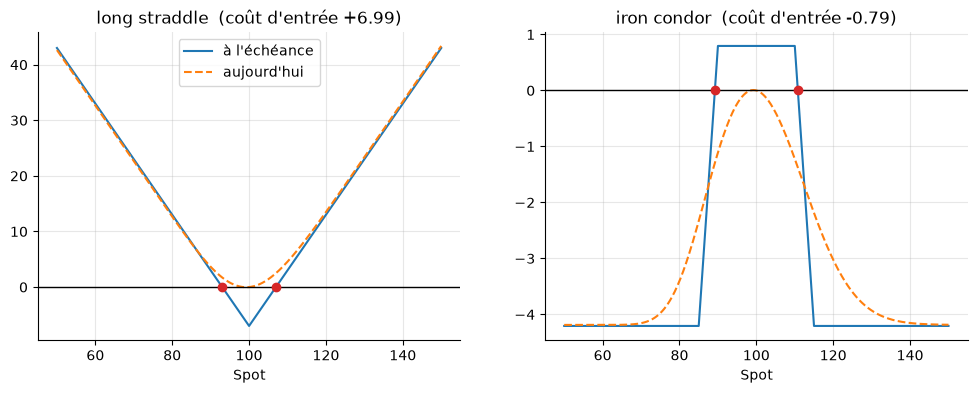

In [3]:
def pnl_curves(legs, grid=np.linspace(50, 150, 401)):
    cost = float(book_value(legs, S0))
    eval_day = min(l.days for l in legs if l.kind != "stock")
    return grid, book_value(legs, grid, elapsed=eval_day) - cost, book_value(legs, grid) - cost, cost

def breakevens(grid, pnl):
    idx = np.where(np.diff(np.sign(pnl)) != 0)[0]
    return [float(grid[i] - pnl[i] * (grid[i + 1] - grid[i]) / (pnl[i + 1] - pnl[i])) for i in idx]

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=False)
for ax, name in zip(axes, ["long straddle", "iron condor"]):
    grid, at_exp, now, cost = pnl_curves(STRATS[name])
    ax.plot(grid, at_exp, label="à l'échéance"); ax.plot(grid, now, "--", label="aujourd'hui")
    ax.axhline(0, color="k", lw=1)
    for b in breakevens(grid, at_exp):
        ax.plot([b], [0], "o", color="C3")
    ax.set(title=f"{name}  (coût d'entrée {cost:+.2f})", xlabel="Spot")
axes[0].legend();

## 3. P&L explain

Book : **short strangle** (vendre call 110 et put 90, 45 jours). Scénario : spot +5 %, vol +3 points, 1 jour qui passe. On compare le **vrai P&L** (réévaluation complète) à l'explication par les grecques.

In [4]:
book = [Leg("call", -1, 110, 45), Leg("put", -1, 90, 45)]
gr = net_greeks(book)
dS, dvol, days = 0.05 * S0, 3, 1

v0 = float(book_value(book, S0))
actual = float(book_value(book, S0 + dS, SIGMA + dvol / 100, days)) - v0

contrib = {
    "Delta  (Δ·ΔS)":    gr["delta"] * dS,
    "Gamma  (½·Γ·ΔS²)": 0.5 * gr["gamma"] * dS**2,
    "Vega   (ν·Δσ)":    gr["vega"] * dvol,
    "Theta  (Θ·jours)": gr["theta"] * days,
}
explained = sum(contrib.values())
explain = pd.Series(contrib)
explain["= Expliqué"] = explained
explain["Vrai P&L"] = actual
explain["Résidu"] = actual - explained
explain.to_frame("P&L")

,P&L
Delta (Δ·ΔS),-0.2977
Gamma (½·Γ·ΔS²),-0.5930
Vega (ν·Δσ),-0.4387
Theta (Θ·jours),0.0410
= Expliqué,-1.2884
Vrai P&L,-1.3337
Résidu,-0.0452


Le résidu vient des termes d'ordre supérieur et croisés. On peut en capturer une partie avec les **grecques de 2ᵉ ordre** (leçon « Grecques de 2ᵉ ordre », fonction `g.second_order`) : vanna (Δ × σ), volga (σ × σ), charm (Δ × temps).

In [5]:
so = {"vanna": 0.0, "volga": 0.0, "charm": 0.0}
for l in book:
    out = g.second_order(S0, l.K, l.days / 365, R, SIGMA, l.kind)
    for k in so:
        so[k] += l.qty * float(out[k])

extra = {
    "Vanna (vanna·Δσ·ΔS)":        so["vanna"] * dvol * dS,
    "Volga (½·volga·Δσ²)":        0.5 * so["volga"] * dvol**2,
    "Charm (charm·jours·ΔS)":     so["charm"] * days * dS,
}
resid2 = actual - explained - sum(extra.values())
pd.Series({**extra, "Résidu avant": actual - explained, "Résidu après": resid2}).to_frame("P&L")

,P&L
Vanna (vanna·Δσ·ΔS),-0.0325
Volga (½·volga·Δσ²),-0.0336
Charm (charm·jours·ΔS),0.0050
Résidu avant,-0.0452
Résidu après,0.0159


## 4. Carte de risque : P&L selon (spot, vol)

Un desk regarde souvent une **grille de scénarios**. Ici : le P&L d'un long straddle après 1 jour, pour des chocs de spot et de vol.

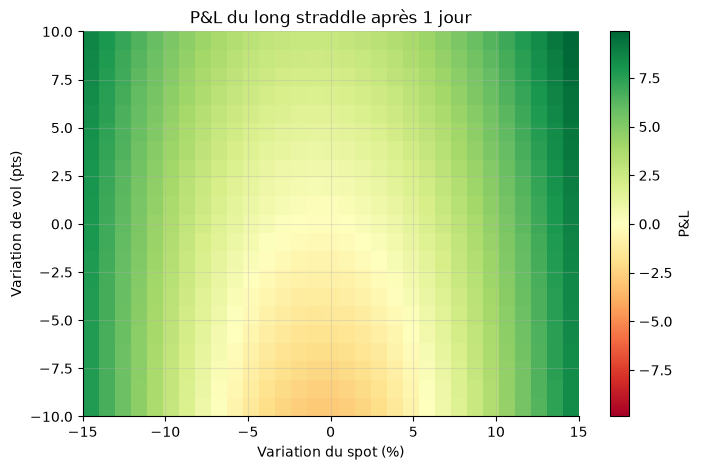

In [6]:
straddle = STRATS["long straddle"]
v0 = float(book_value(straddle, S0))
spots = np.linspace(-15, 15, 31)           # % de variation du spot
vols = np.linspace(-10, 10, 21)            # points de vol
grid = np.array([[float(book_value(straddle, S0 * (1 + s / 100), SIGMA + v / 100, 1)) - v0 for s in spots] for v in vols])

fig, ax = plt.subplots(figsize=(8, 5))
lim = np.abs(grid).max()
im = ax.imshow(grid, origin="lower", aspect="auto", cmap="RdYlGn", vmin=-lim, vmax=lim,
               extent=[spots[0], spots[-1], vols[0], vols[-1]])
ax.set(xlabel="Variation du spot (%)", ylabel="Variation de vol (pts)", title="P&L du long straddle après 1 jour")
fig.colorbar(im, label="P&L");

### À toi de jouer

1. Ajoute un **calendar spread** (vendre call 100 à 30 jours, acheter call 100 à 90 jours) à `STRATS` et compare ses grecques à celles du straddle. Attention : `pnl_curves` mesure à la *première* échéance.
2. Dans le P&L explain, passe `dS` à 15 % : le résidu augmente-t-il ? Pourquoi (ordre supérieur) ?
3. Dessine la carte de risque de l'iron condor : où est la zone de perte maximale ?